# Results viewer for budget runs

The plots of `Results_Viewer.ipynb`, for runs made to a budget of row reads (`budget=` in the experiment list): the same colours, panels and mean ± std bands, read straight from the run directory as it is on disk.

What differs from `Results_Viewer.ipynb`, and why:
- **Row reads are the main x-axis**, in full-data passes (row reads / N). A budget run stores its states at evenly spaced row-read marks, so every chain has a record at the same cost and the mean ± std is over chains at equal cost.
- **Iterations and time are per chain.** In a budget run each chain reaches a mark at its own iteration, so the metrics file's `iterations` (chain 0's alone) is not used. Each chain's iteration, time and tree size are read from its own `Run_N` group, and they are averaged on a shared grid that stops where the shortest chain stops, as `Results_Viewer.ipynb` does for time.
- `init_tree_size: null` in `config.json` means a start from the prior (`_init-prior` files), not a stump.
- MCMC only: there is no move log in a budget run, so the move-outcome sections are left out.

In [1]:
import os
import re
import json
import hashlib
import numpy as np
import h5py
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams.update({'text.usetex': False})

RESULTS_ROOT = "Results"
RUN_ID = "overnight_viewer"      # a directory under Results/ with config.json, *.h5 and *_metrics.npz

In [2]:
import hashlib

def parse_ss(tag):
    """The {ss} field of a filename back to ss_prop: '12p5' -> 0.125, '50' -> 0.5."""
    return float(tag.replace("p", ".")) / 100


def load_config(timestamp, results_root="Results"):
    # load the config json for the given timestamp
    config_path = os.path.join(results_root, timestamp, "config.json")
    with open(config_path, "r") as f:
        config = json.load(f)
    return config


def config_stems(entry):
    """The file stems one config.json entry's runs were written under, built
    the way results_io.experiment_stem names them: an entry may list several
    samplers and proposals, and each pair has its own files."""
    def as_list(value):
        return [value] if isinstance(value, str) else list(value)

    # What the runs started from: nothing for a stump, _init<N> for a random
    # N-node tree, _init-prior for draws from the prior, _init-<name> for a
    # given one -- named by a digest of its rows when the entry does not name
    # it (results_io.init_of). An entry without init_tree_size predates the
    # prior default and started from a stump.
    rows = entry.get("init_tree")
    if rows is None:
        # A key holding None means a start from the prior (_init-prior); no key
        # at all is a config from before the prior start, which meant a stump.
        size = entry["init_tree_size"] if "init_tree_size" in entry else 0
        if size is None:
            init = "_init-prior"
        elif isinstance(size, str):
            init = f"_init-{size}"
        else:
            init = f"_init{int(size)}" if size else ""
    else:
        name = entry.get("init_tree_name")
        if not name:
            canonical = sorted([int(r[0]), int(r[1]), int(r[2]), int(r[3]), float(r[4])]
                               for r in rows)
            name = "t" + hashlib.sha1(json.dumps(canonical).encode()).hexdigest()[:8]
        init = f"_init-{name}"

    stems = []
    for sampler in as_list(entry.get("samplers", ())):
        for proposal in as_list(entry.get("proposals", ())):
            # MH takes no subsample and is always tagged 100.
            ss_prop = 1.0 if proposal == "MH" else entry.get("ss_prop")
            if ss_prop is None or "dataset" not in entry:
                continue
            ss = f"{round(100 * ss_prop, 6):g}".replace(".", "p")
            stems.append(f"{entry['dataset']}_{sampler}_{proposal}_{ss}{init}")
    return stems


def load_metrics_files(timestamp, results_root="Results"):
    """(smc, mcmc) lists of dicts, one per *_metrics.npz in the run directory
    that config.json has an experiment for. Each carries that experiment's
    chains, particles (None for MCMC) and max_tree_size; a metrics file no
    experiment in the config accounts for is skipped."""
    results_path = os.path.join(results_root, timestamp)
    PROPOSALS = {"MH": "MH", "DA": "DA", "FlatHINTS": "Flat HINTS", "HINTS": "HINTS","HINTSProxy": "HINTS Proxy"}
    smc_samplers = []
    mcmc_samplers = []

    # run_experiments.py writes a list of experiments, a single
    # sampler_diagnostics.py sweep the one config it ran.
    config = load_config(timestamp, results_root)
    entries = config.get("experiments") or ([config] if "dataset" in config else [])
    config_of = {stem: entry for entry in entries for stem in config_stems(entry)}
    skipped = []

    for filename in sorted(os.listdir(results_path)):
        if not filename.endswith("_metrics.npz"):
            continue

        # Split from the right: only the last three fields are in a fixed
        # position, so a dataset name with "_" in it still parses.
        stem = filename[:-len("_metrics.npz")]
        entry = config_of.get(stem)
        if entry is None:
            skipped.append(filename)
            continue
        # A run started from a random tree carries a trailing _init<N>, one
        # started from a given tree _init-<name>; a run started from a stump
        # has neither.
        fields, init_tree_size, init_tree_name = stem, 0, None
        head, _, last = stem.rpartition("_")
        if last.startswith("init-") and len(last) > len("init-"):
            fields, init_tree_name = head, last[len("init-"):]
        elif last.startswith("init") and last[len("init"):].isdigit():
            fields, init_tree_size = head, int(last[len("init"):])
        dataset, sampler, proposal, ss = fields.rsplit("_", 3)
        # MH runs on the full data -- None keeps it apart from the subsampled runs.
        ss_prop = None if proposal == "MH" else parse_ss(ss)

        file_path = os.path.join(results_path, filename)
        with np.load(file_path) as npz:
            # Read the arrays out now: np.load is lazy and holds the file open.
            data = {key: npz[key] for key in npz.files}

        sampler_dict = {
            "name": stem,
            "dataset": dataset,
            "ss_prop": ss_prop,
            "init_tree_size": init_tree_size,
            "init_tree_name": init_tree_name,
            "sampler": sampler,
            "proposal_mechanism": PROPOSALS.get(proposal, proposal),
            "path": file_path,
            "h5_path": os.path.join(results_path, stem + ".h5"),
            # Every stride-th stored record was evaluated (80 for smc_MH_100, 1
            # for the rest). data['iterations'] already holds the iteration /
            # step each evaluated point came from, so plot against that rather
            # than against the point's index.
            "stride": int(data["stride"]),
            "data": data,
            # From the matching config.json experiment. An entry may leave any
            # of these out, which reads as None here.
            # init_tree is the starting tree itself, as [node, left, right,
            # feat, thr] rows -- None unless the runs were given one.
            "init_tree": entry.get("init_tree"),
            "chains": entry.get("chains"),
            "particles": entry.get("particles") if sampler == "smc" else None,
            "max_tree_size": entry.get("max_tree_size"),
        }

        if sampler == "smc":
            smc_samplers.append(sampler_dict)
        else:
            mcmc_samplers.append(sampler_dict)

    if skipped:
        print(f"Skipped {len(skipped)} metrics file(s) with no matching experiment "
              f"in config.json: {', '.join(skipped)}")
    return smc_samplers, mcmc_samplers

In [3]:
def budget_series(experiment):
    """Per-chain series read from the .h5, lined up with the metric arrays:
    the row-read mark of each record, each chain's iteration and cumulative
    sampling time at it, and the tree size (internal nodes). A chain that
    stopped at its iteration cap before the budget has fewer records; its
    series are padded with NaN, as its metrics are."""
    n_runs = int(experiment['data']['n_runs'])
    n_rec = len(experiment['data']['iterations'])
    pick = np.arange(n_rec) * experiment['stride']

    def padded(column):
        values = column[()]
        out = np.full(n_rec, np.nan)
        ok = pick[pick < len(values)]
        out[:len(ok)] = values[ok]
        return out

    with h5py.File(experiment['h5_path'], "r") as f:
        runs = sorted((k for k in f if k.startswith("Run_")), key=lambda k: int(k[len("Run_"):]))[:n_runs]
        experiment['budget'] = float(f[runs[0]].attrs['budget'])
        r0 = f[runs[0]]
        experiment['n_train'] = int(np.asarray(r0["state_leaf_counts"][:r0["state_leaf_lengths"][0]]).sum())
        for key, column in (('iteration', 'iteration'), ('time', 'cumulative_time'),
                            ('tree_len', 'n_nodes'), ('row_reads', 'row_reads')):
            experiment[key] = np.stack([padded(f[r][column]) for r in runs])
    # Record k is taken at the first iteration whose row reads reach mark k + 1.
    experiment['marks'] = (pick + 1) * experiment['budget'] / experiment['entry']['records']


smc_results, mcmc_results = load_metrics_files(RUN_ID, RESULTS_ROOT)
if smc_results:
    print(f"{len(smc_results)} SMC experiment(s) left out: this notebook is for MCMC budget runs.")
config = load_config(RUN_ID, RESULTS_ROOT)
entry_of = {stem: e for e in config.get("experiments", []) for stem in config_stems(e)}
for experiment in mcmc_results:
    experiment['entry'] = entry_of[experiment['name']]
    budget_series(experiment)

print(f"{len(mcmc_results)} MCMC experiments in {RUN_ID}:")
for e in mcmc_results:
    print(f"  {e['name']:40s} chains {e['data']['n_runs']:>3}  records {e['row_reads'].shape[1]:>5}  "
          f"budget {e['budget']:.0e}  N = {e['n_train']:,}")

13 MCMC experiments in overnight_viewer:
  susy_mcmc_DA_0p78125_init-prior          chains   8  records  1000  budget 2e+10  N = 3,999,999
  susy_mcmc_DA_12p5_init-prior             chains   8  records  5000  budget 1e+11  N = 3,999,999
  susy_mcmc_DA_1p5625_init-prior           chains   8  records  1000  budget 2e+10  N = 3,999,999
  susy_mcmc_DA_25_init-prior               chains   8  records  5000  budget 1e+11  N = 3,999,999
  susy_mcmc_DA_3p125_init-prior            chains   8  records  5000  budget 1e+11  N = 3,999,999
  susy_mcmc_DA_6p25_init-prior             chains   8  records  5000  budget 1e+11  N = 3,999,999
  susy_mcmc_HINTS_0p78125_init-prior       chains   8  records  1000  budget 2e+10  N = 3,999,999
  susy_mcmc_HINTS_12p5_init-prior          chains   8  records  1000  budget 2e+10  N = 3,999,999
  susy_mcmc_HINTS_1p5625_init-prior        chains   8  records  1000  budget 2e+10  N = 3,999,999
  susy_mcmc_HINTS_25_init-prior            chains   8  records  1000  budget 

In [4]:
PROPOSAL_ORDER = ["DA", "Flat HINTS", "HINTS Proxy", "HINTS", "MH"]


def omega_text(ss_prop):
    return "1" if ss_prop is None else f"1/{round(1 / ss_prop)}"


def hierarchy_of(experiment):
    """The HINTS hierarchy in Chapter 2's notation [m_0, m_1, ...]."""
    e = experiment['entry']
    if e.get('hierarchy'):
        return list(e['hierarchy'])
    levels = e.get('levels', 2)
    branching = e.get('branching') or round(round(1 / experiment['ss_prop']) ** (1 / max(levels, 1)))
    return [1] + [branching] * levels


def label_of(experiment):
    p = experiment['proposal_mechanism']
    if p in ("HINTS", "HINTS Proxy"):
        return f"{p} (Hierarchy={hierarchy_of(experiment)}, ω={omega_text(experiment['ss_prop'])})"
    if p == "Flat HINTS":
        return f"Flat HINTS (ω={omega_text(experiment['ss_prop'])})"
    if p == "DA":
        return f"DA (ω={omega_text(experiment['ss_prop'])})"
    return p


mcmc_results.sort(key=lambda e: (PROPOSAL_ORDER.index(e['proposal_mechanism']),
                                 -(e['ss_prop'] or 1.0)))
for e in mcmc_results:
    print(label_of(e))

DA (ω=1/4)
DA (ω=1/8)
DA (ω=1/16)
DA (ω=1/32)
DA (ω=1/64)
DA (ω=1/128)
HINTS (Hierarchy=[1, 2, 2], ω=1/4)
HINTS (Hierarchy=[1, 2, 2, 2], ω=1/8)
HINTS (Hierarchy=[1, 2, 2, 2, 2], ω=1/16)
HINTS (Hierarchy=[1, 2, 2, 2, 2, 2], ω=1/32)
HINTS (Hierarchy=[1, 2, 2, 2, 2, 2, 2], ω=1/64)
HINTS (Hierarchy=[1, 2, 2, 2, 2, 2, 2, 2], ω=1/128)
MH


In [5]:
# The colours of Results_Viewer.ipynb, with two more so that up to seven block
# sizes of one proposal each keep a colour of their own.
line_colours = {
    'MH':    ['#009E73'],
    'DA':    ['#E69F00', '#56B4E9', '#CC79A7', '#F0E442', '#0072B2', '#D55E00', '#7F7F7F'],
}
shade_colours = {
    'MH':    ['#99D8C7'],
    'DA':    ['#F2BF99', '#BBE1F6', '#D9A3D9', '#FAF4B3', '#99C7E0', '#EEB399', '#CCCCCC'],
}
for p in ("HINTS", "HINTS Proxy", "Flat HINTS"):
    line_colours[p], shade_colours[p] = line_colours['DA'], shade_colours['DA']

X_LABELS = {"passes": "Full-data passes (row reads / N)", "iteration": "Iteration",
            "time": "Sampling time (s)"}


def colour_index(experiment, results):
    """Rank of this experiment's block size among its proposal's, largest
    block first, so each block size keeps one colour in every plot."""
    p = experiment['proposal_mechanism']
    sizes = sorted({e['ss_prop'] for e in results if e['proposal_mechanism'] == p},
                   key=lambda s: -(s or 1.0))
    return sizes.index(experiment['ss_prop']) % len(line_colours[p])


def series(experiment, key):
    data = experiment['data']
    return data[key] if key in data else experiment[key]     # (n_runs, n_records)


def curve(experiment, key, x="passes", n_grid=500, min_share=0.75):
    """(x values, mean, std) of a metric across chains. Against passes every
    chain has a record at every mark (until a chain that stopped at its
    iteration cap runs out), and points where fewer than min_share of the chains
    have a value are dropped. Against iteration or time each chain has its own
    x, so they are averaged on a grid that stops where the shortest chain stops,
    each chain holding the value of its last record."""
    values = series(experiment, key)
    if x == "passes":
        keep = np.isfinite(values).mean(axis=0) >= min_share
        v = values[:, keep]
        return (experiment['marks'][keep] / experiment['n_train'],
                np.nanmean(v, axis=0), np.nanstd(v, axis=0))
    xs = experiment[x]
    lasts = [t[np.isfinite(t)][-1] for t in xs]
    grid = np.linspace(np.nanmax(xs[:, 0]), min(lasts), n_grid)
    at_grid = []
    for t, v in zip(xs, values):
        fin = np.isfinite(t) & np.isfinite(v)
        t, v = t[fin], v[fin]
        at_grid.append(v[np.clip(np.searchsorted(t, grid, side="right") - 1, 0, None)])
    at_grid = np.stack(at_grid)
    return grid, at_grid.mean(axis=0), at_grid.std(axis=0)


# One colour per proposal, for plots that put proposals side by side at one block size.
PROPOSAL_COLOURS = {"DA": ("#E69F00", "#F2BF99"), "Flat HINTS": ("#CC79A7", "#D9A3D9"),
                    "HINTS Proxy": ("#56B4E9", "#BBE1F6"), "HINTS": ("#0072B2", "#99C7E0"),
                    "MH": ("#009E73", "#99D8C7")}


def band(ax, experiment, results, key, x, xmax=None, by_proposal=False):
    p = experiment['proposal_mechanism']
    k = colour_index(experiment, results)
    xs, mean, std = curve(experiment, key, x)
    if xmax is not None:
        keep = xs <= xmax
        xs, mean, std = xs[keep], mean[keep], std[keep]
    lo, hi = mean - std, mean + std
    if key == "tree_len":
        lo, hi = np.maximum(lo, 0), np.minimum(hi, experiment['max_tree_size'] or np.inf)
    line, shade = PROPOSAL_COLOURS[p] if by_proposal else (line_colours[p][k], shade_colours[p][k])
    ax.fill_between(xs, lo, hi, color=shade, alpha=0.5, zorder=1)
    ax.plot(xs, mean, label=label_of(experiment), color=line, zorder=2)


def plot_metric_split(results, key, title, ylabel, x="passes", xlim=None, yscale=None, logx=False,
                      sharey=True):
    """One panel per subsampling proposal, with MH on every panel, as in
    Results_Viewer.ipynb."""
    panels = [p for p in PROPOSAL_ORDER if p != "MH" and any(e['proposal_mechanism'] == p for e in results)]
    fig, axes = plt.subplots(1, len(panels), figsize=(10 * len(panels), 6), sharey=sharey, squeeze=False)
    axes = axes[0]
    for ax, p in zip(axes, panels):
        for e in results:
            if e['proposal_mechanism'] in (p, "MH"):
                band(ax, e, results, key, x)
        ax.set_title(p)
        ax.set_xlabel(X_LABELS[x])
        ax.set_ylabel(ylabel)
        if xlim:
            ax.set_xlim(xlim)
        if yscale:
            ax.set_yscale(yscale)
        if logx:
            ax.set_xscale("log")
        ax.legend(fontsize=9)
    n_runs = sorted({int(e['data']['n_runs']) for e in results})
    fig.suptitle(f"MCMC {title} by {x} on {results[0]['dataset']}, mean ± std over "
                 f"{'/'.join(map(str, n_runs))} chains ({RUN_ID})")
    plt.show()


def plot_by_omega(results, key, title, ylabel, x="passes", xlim=None, logx=False):
    """Not in Results_Viewer.ipynb: one panel per block size, every proposal
    run at it side by side, with MH on every panel."""
    omegas = sorted({e['ss_prop'] for e in results if e['ss_prop'] is not None}, reverse=True)
    ncols = min(len(omegas), 3)
    nrows = int(np.ceil(len(omegas) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.5 * nrows), sharey=True, squeeze=False)
    for ax in axes.flat[len(omegas):]:
        ax.set_visible(False)
    axes = axes.flat
    for ax, w in zip(axes, omegas):
        for e in results:
            if e['ss_prop'] == w or e['proposal_mechanism'] == "MH":
                band(ax, e, results, key, x, by_proposal=True)
        ax.set_title(f"ω = {omega_text(w)}")
        ax.set_xlabel(X_LABELS[x])
        if xlim:
            ax.set_xlim(xlim)
        if logx:
            ax.set_xscale("log")
        ax.legend(fontsize=8)
        ax.set_ylabel(ylabel)
    fig.suptitle(f"MCMC {title} by {x} at each block size, mean ± std over chains ({RUN_ID})")
    plt.tight_layout()
    plt.show()


def plot_chains(results, key, label, x="passes", xlim=None):
    """Every chain of every experiment, with the mean and ±1 std, as
    Results_Viewer.ipynb's plot_chains."""
    ncols = max(sum(e['proposal_mechanism'] == p for e in results) for p in PROPOSAL_ORDER)
    nrows = int(np.ceil(len(results) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 3.6), sharey=True, squeeze=False)
    for ax in axes.flat[len(results):]:
        ax.set_visible(False)
    for ax, e in zip(axes.flat, results):
        values = series(e, key)
        for j, chain in enumerate(values):
            xs = e['marks'] / e['n_train'] if x == "passes" else e[x][j]
            fin = np.isfinite(xs) & np.isfinite(chain)
            ax.plot(xs[fin], chain[fin], linewidth=1, color="blue", alpha=0.25,
                    label="chain" if j == 0 else None)
        xs, mean, std = curve(e, key, x)
        ax.plot(xs, mean, linewidth=2, color="red", label="mean")
        ax.plot(xs, mean + std, linewidth=2, color="orange", linestyle="--", label="+1 std")
        ax.plot(xs, mean - std, linewidth=2, color="orange", linestyle="--", label="-1 std")
        ax.set_title(label_of(e) if e['proposal_mechanism'] != "MH" else "Metropolis-Hastings", fontsize=10)
        ax.set_xlabel(X_LABELS[x])
        ax.set_ylabel(label)
        if xlim:
            ax.set_xlim(xlim)
    plt.tight_layout()
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"{label} per {x} for MCMC experiments - {RUN_ID}", fontsize=16, y=1.06)
    plt.show()

## MCMC results against row reads (full-data passes)

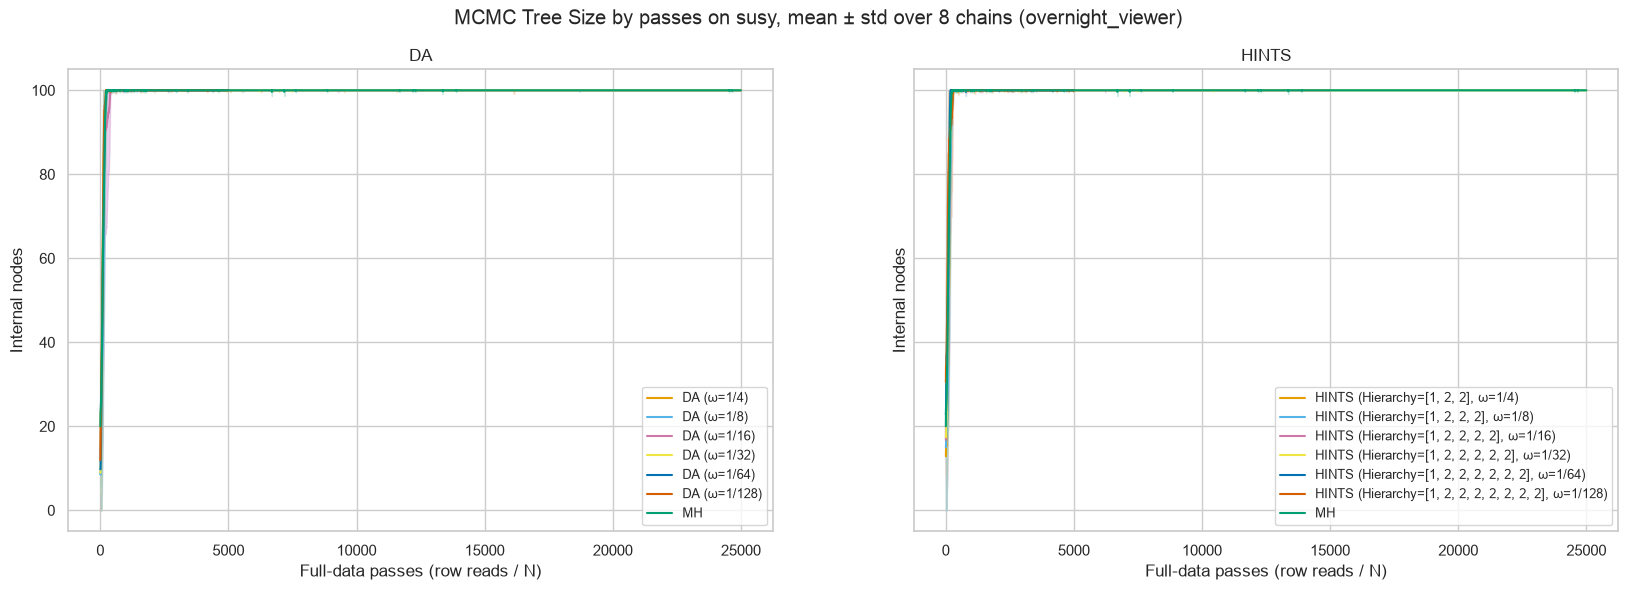

In [ ]:
plot_metric_split(mcmc_results, "tree_len", "Tree Size", "Internal nodes")

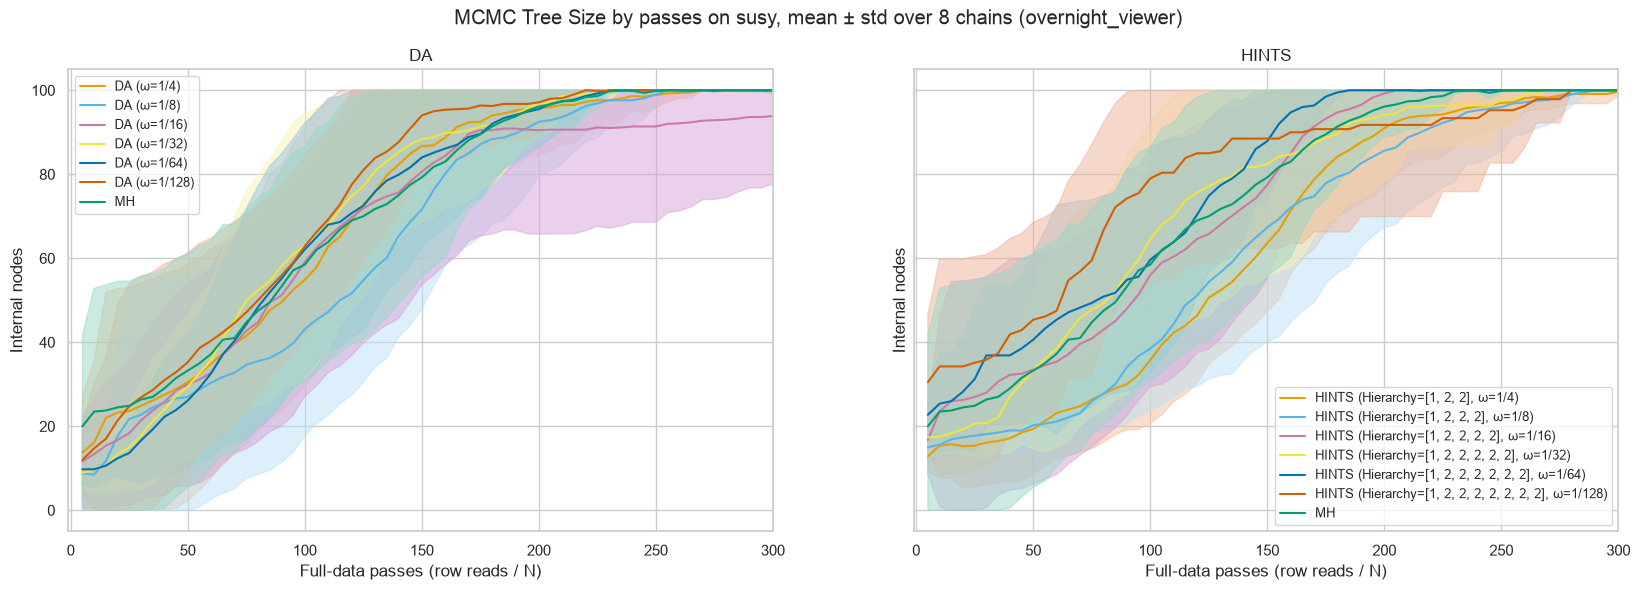

In [32]:
plot_metric_split(mcmc_results, "tree_len", "Tree Size", "Internal nodes",xlim=(-1,300))

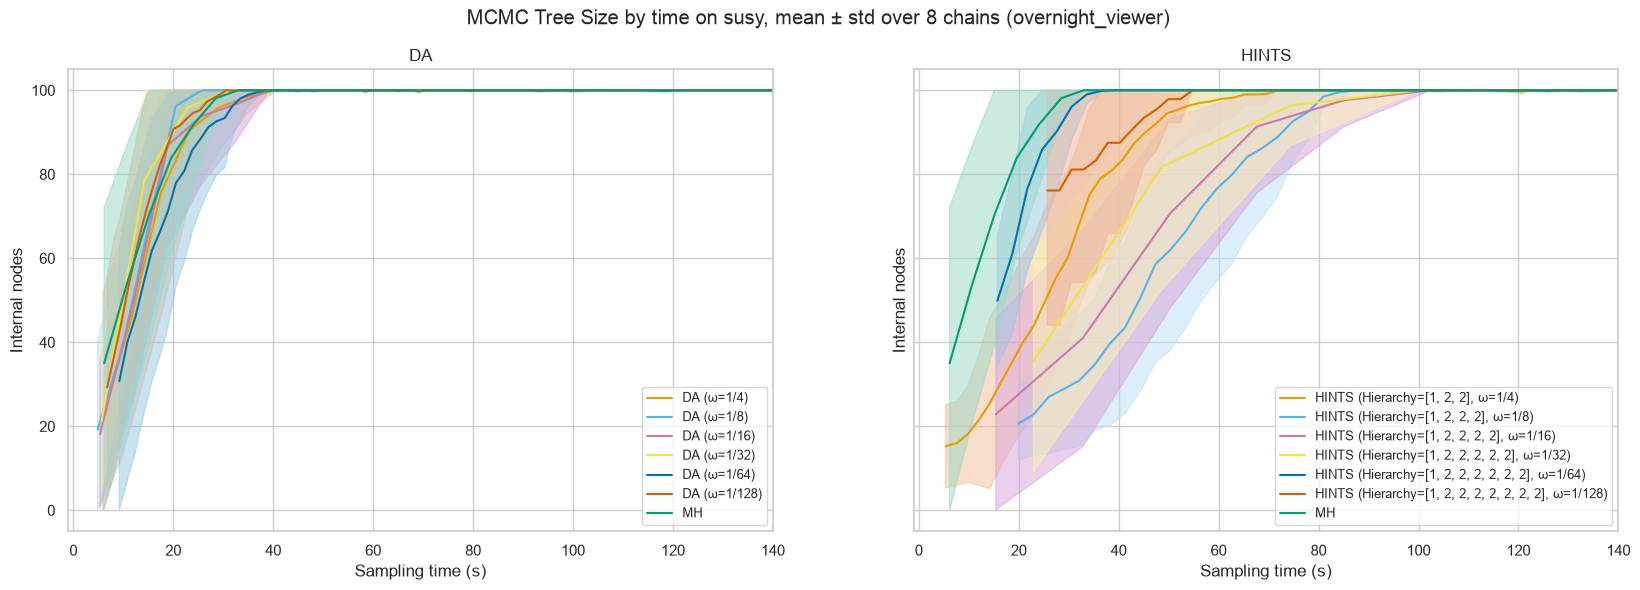

In [27]:
plot_metric_split(mcmc_results, "tree_len", "Tree Size", "Internal nodes", x="time",xlim=(-1,140))

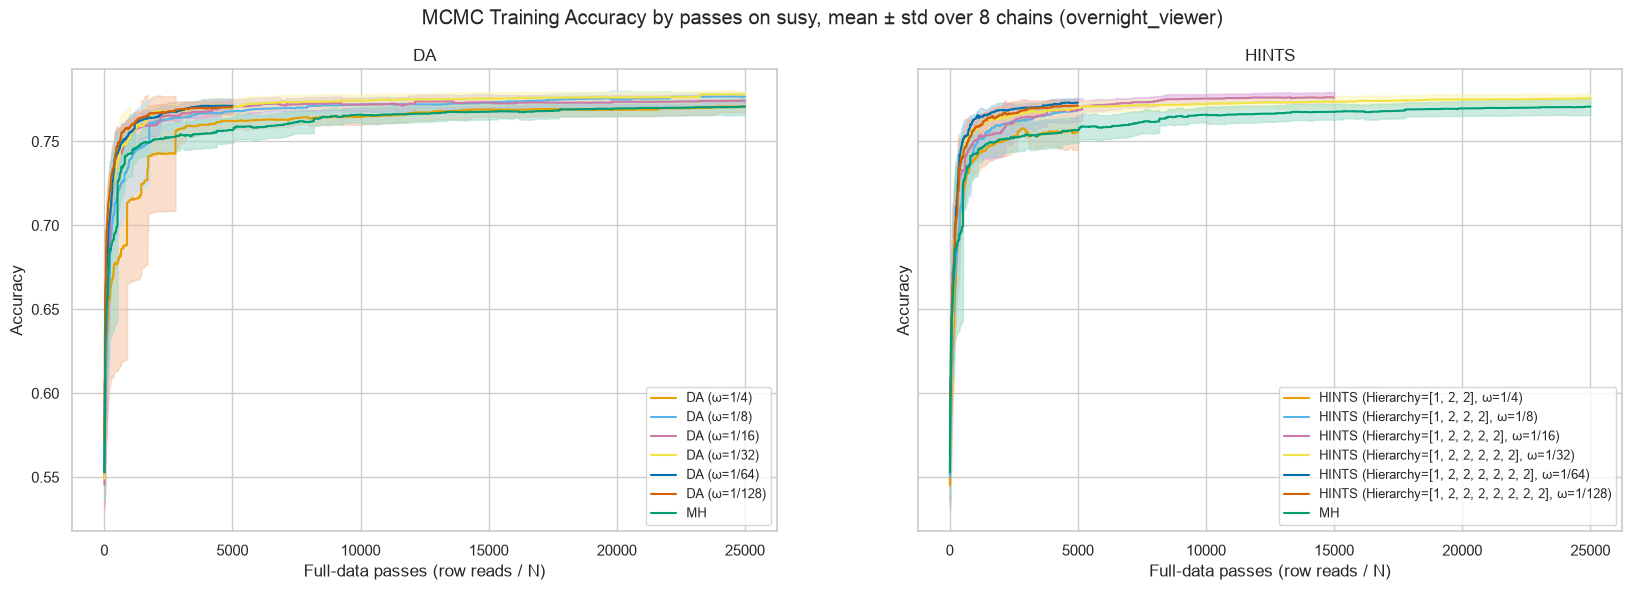

In [7]:
plot_metric_split(mcmc_results, "train_accuracy", "Training Accuracy", "Accuracy")

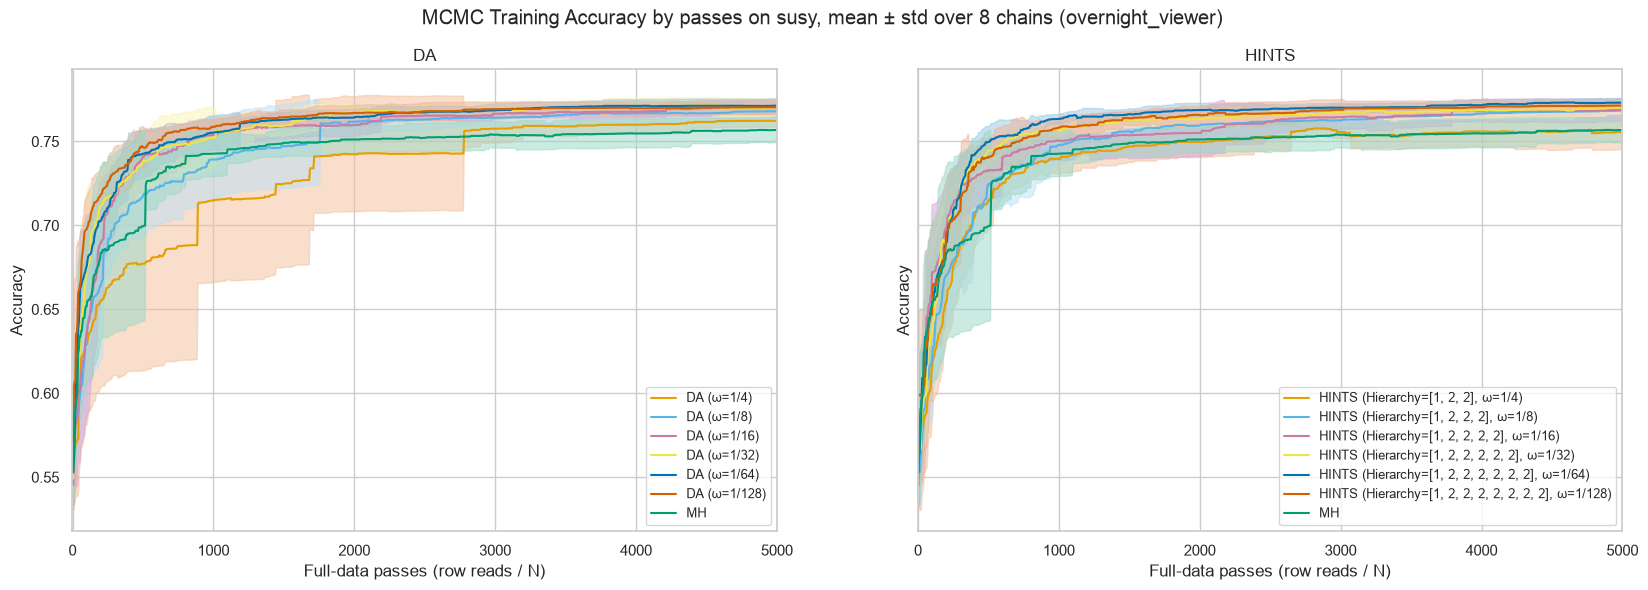

In [35]:
plot_metric_split(mcmc_results, "train_accuracy", "Training Accuracy", "Accuracy",xlim=(-1,5000))

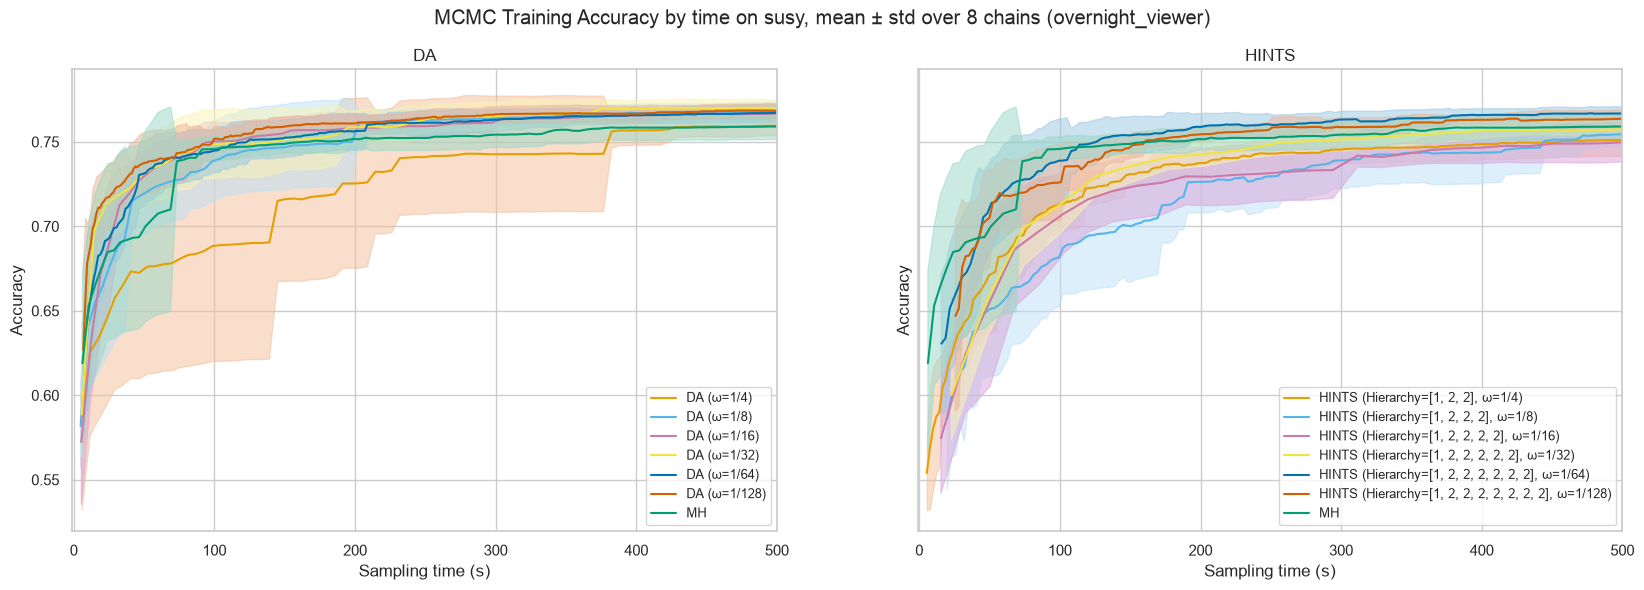

In [30]:
plot_metric_split(mcmc_results, "train_accuracy", "Training Accuracy", "Accuracy", x="time",xlim=(-1,500))

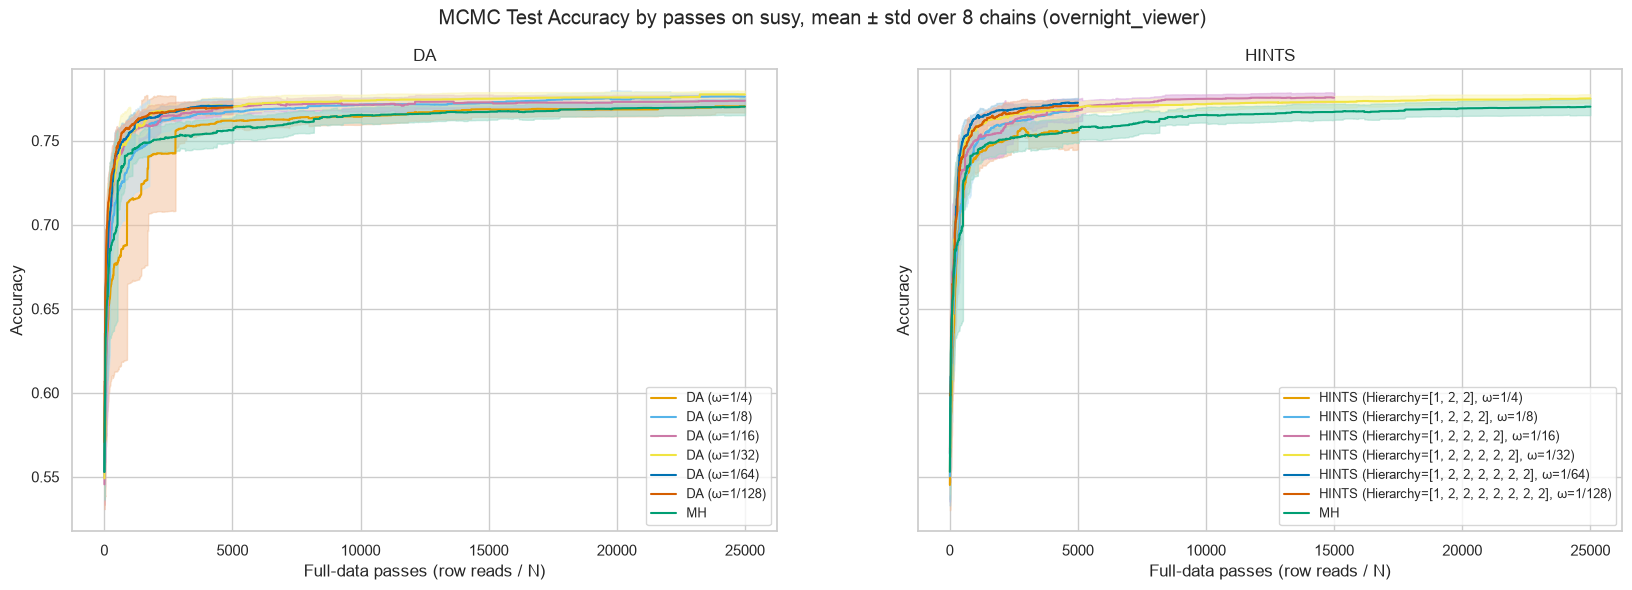

In [8]:
plot_metric_split(mcmc_results, "test_accuracy", "Test Accuracy", "Accuracy")

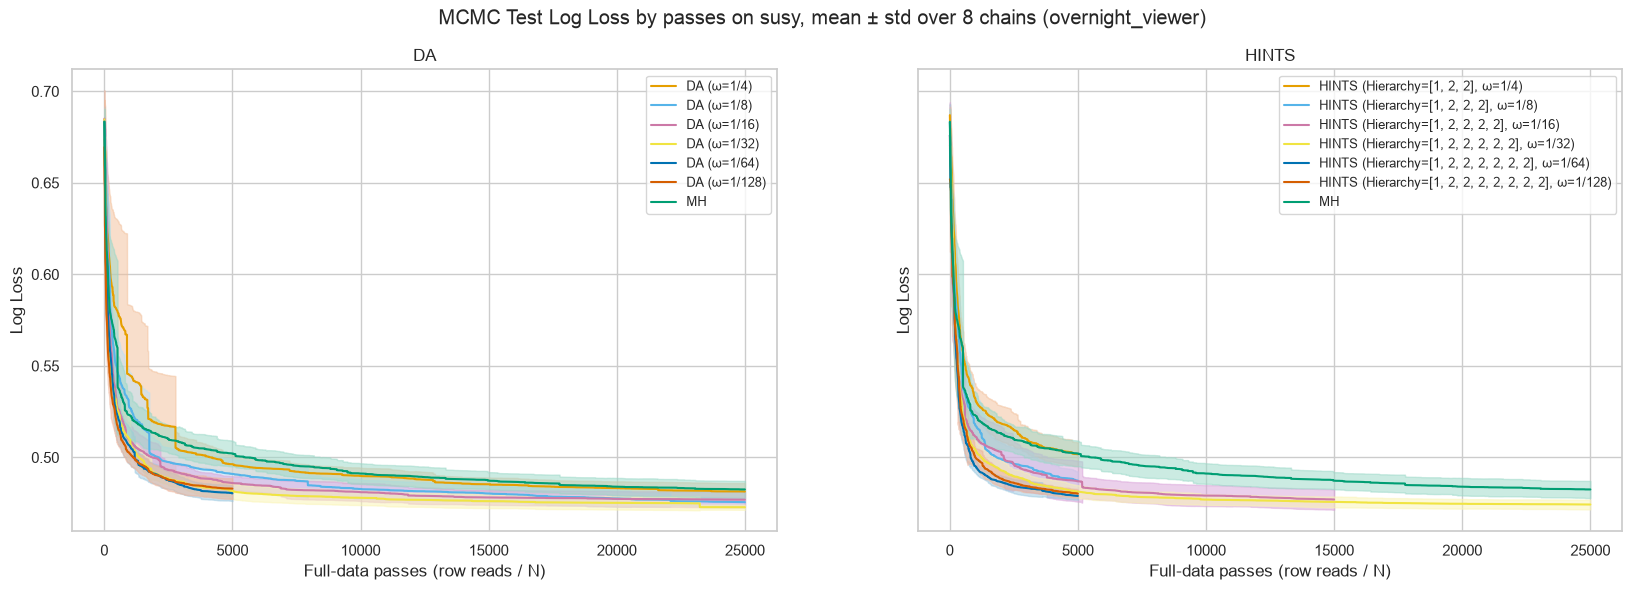

In [9]:
plot_metric_split(mcmc_results, "test_log_loss", "Test Log Loss", "Log Loss")

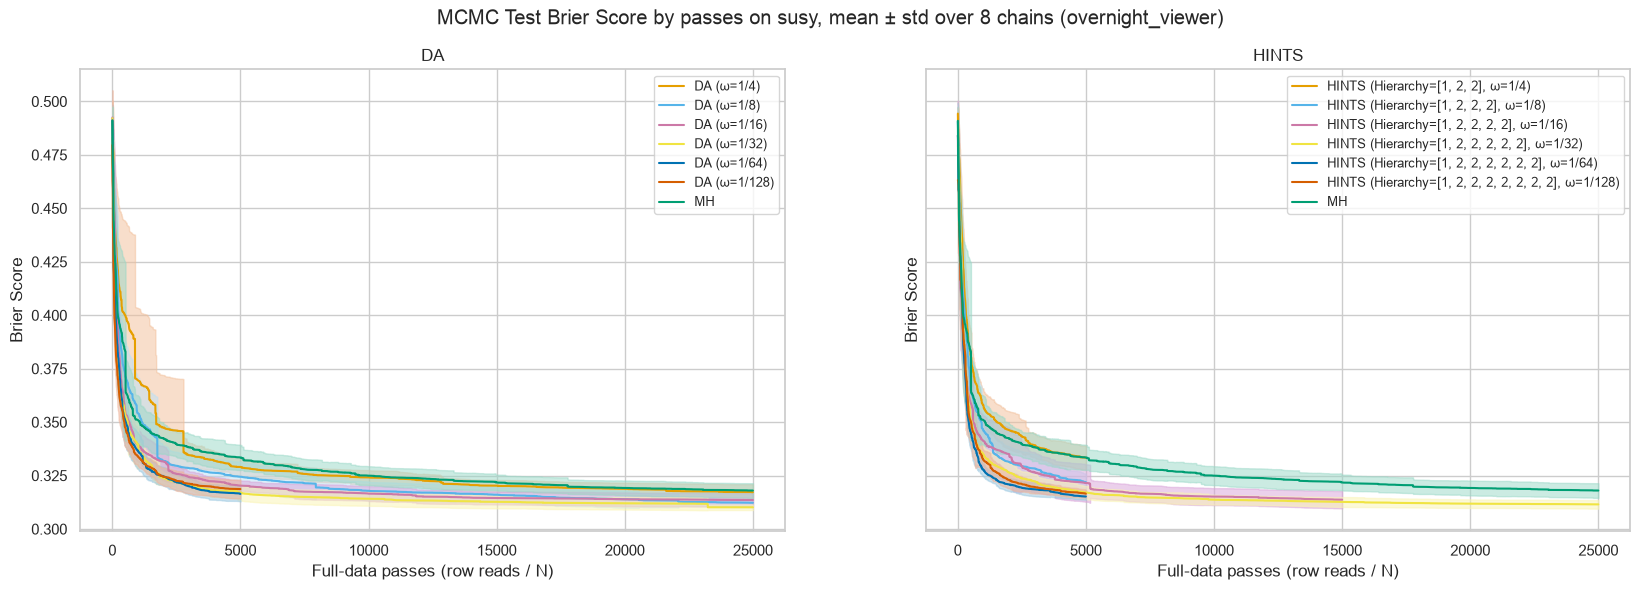

In [10]:
plot_metric_split(mcmc_results, "test_brier", "Test Brier Score", "Brier Score")

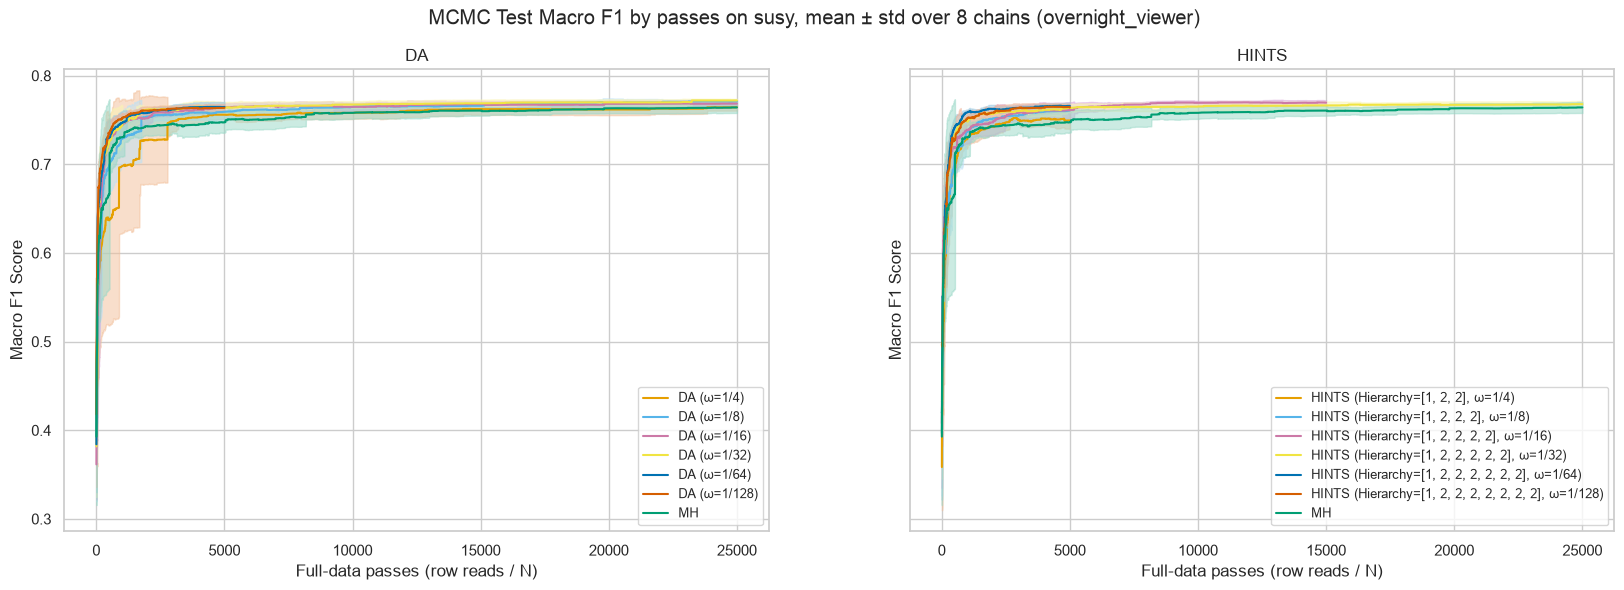

In [11]:
plot_metric_split(mcmc_results, "test_macro_f1", "Test Macro F1", "Macro F1 Score")

### Each block size on its own panel

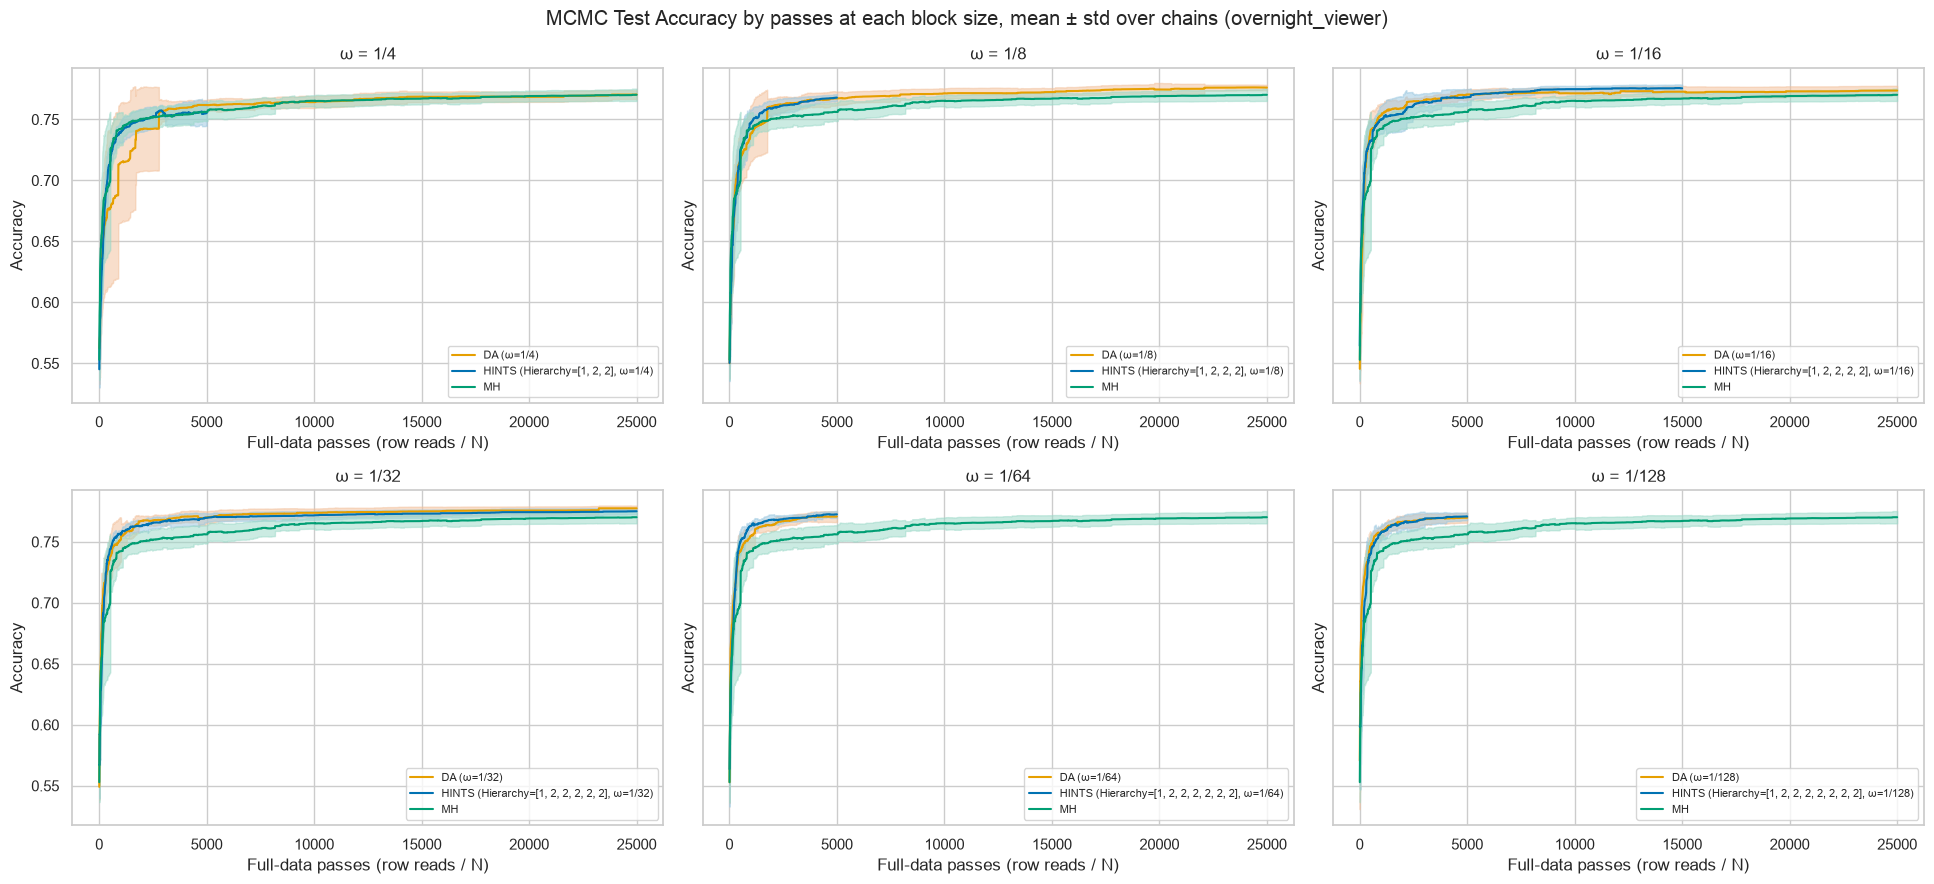

In [12]:
plot_by_omega(mcmc_results, "test_accuracy", "Test Accuracy", "Accuracy")

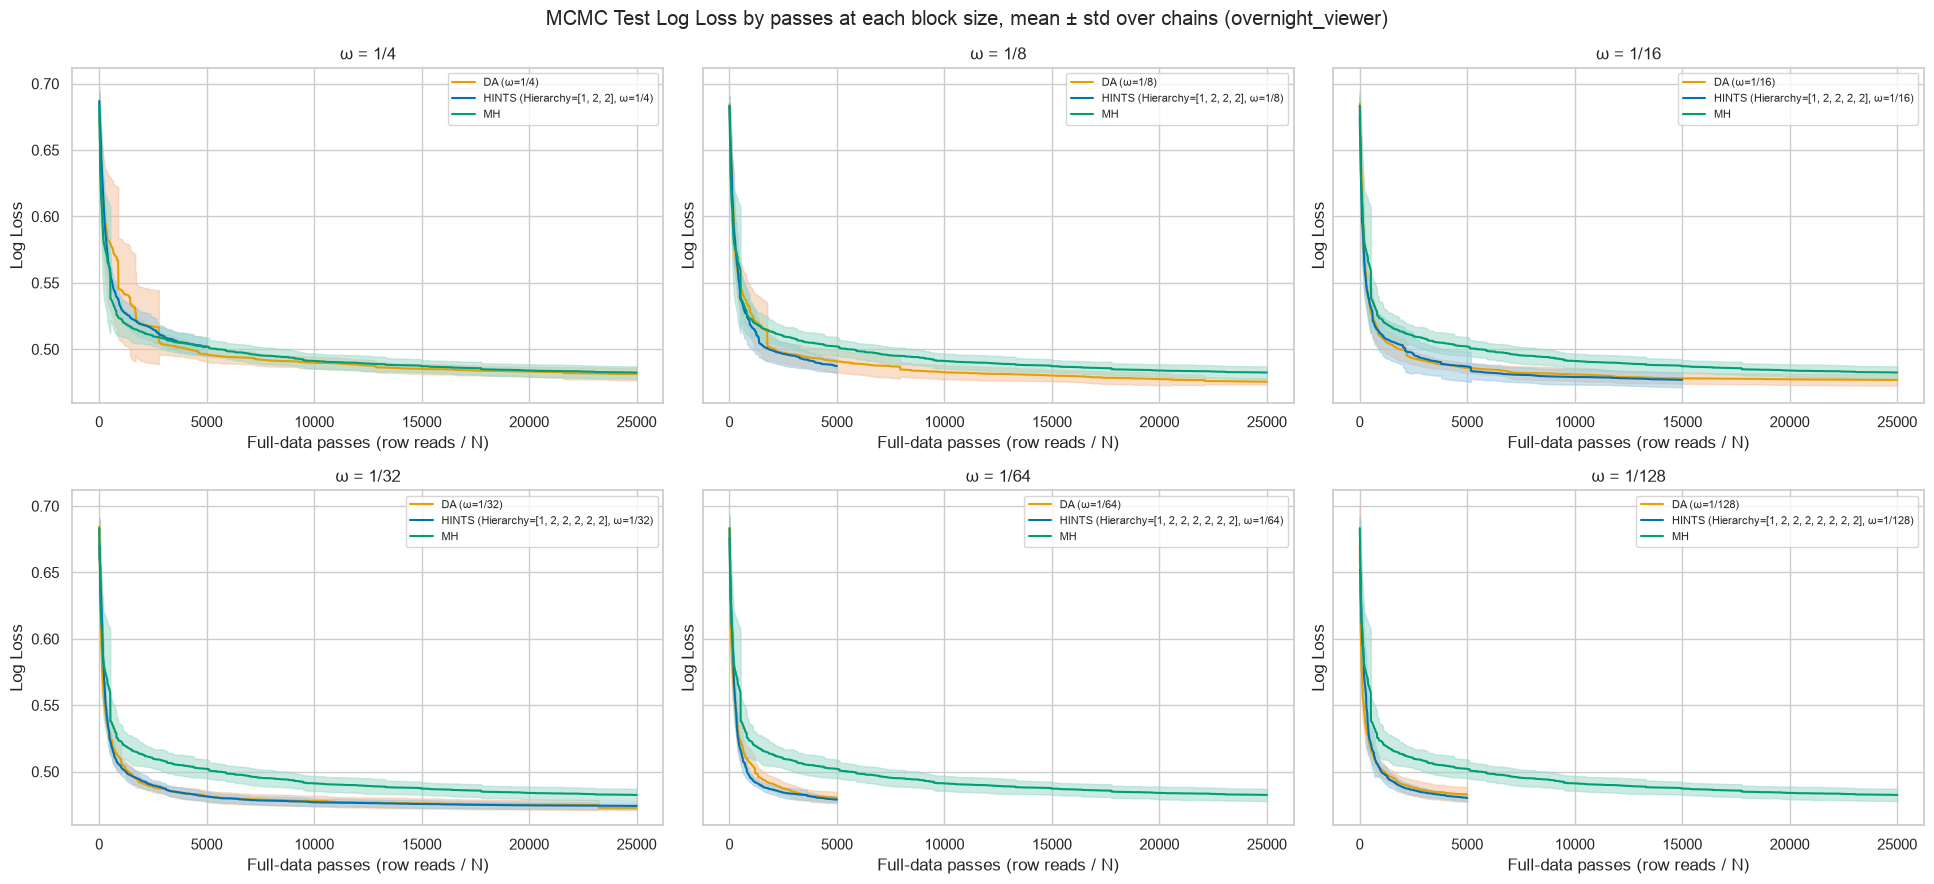

In [13]:
plot_by_omega(mcmc_results, "test_log_loss", "Test Log Loss", "Log Loss")

## Every chain

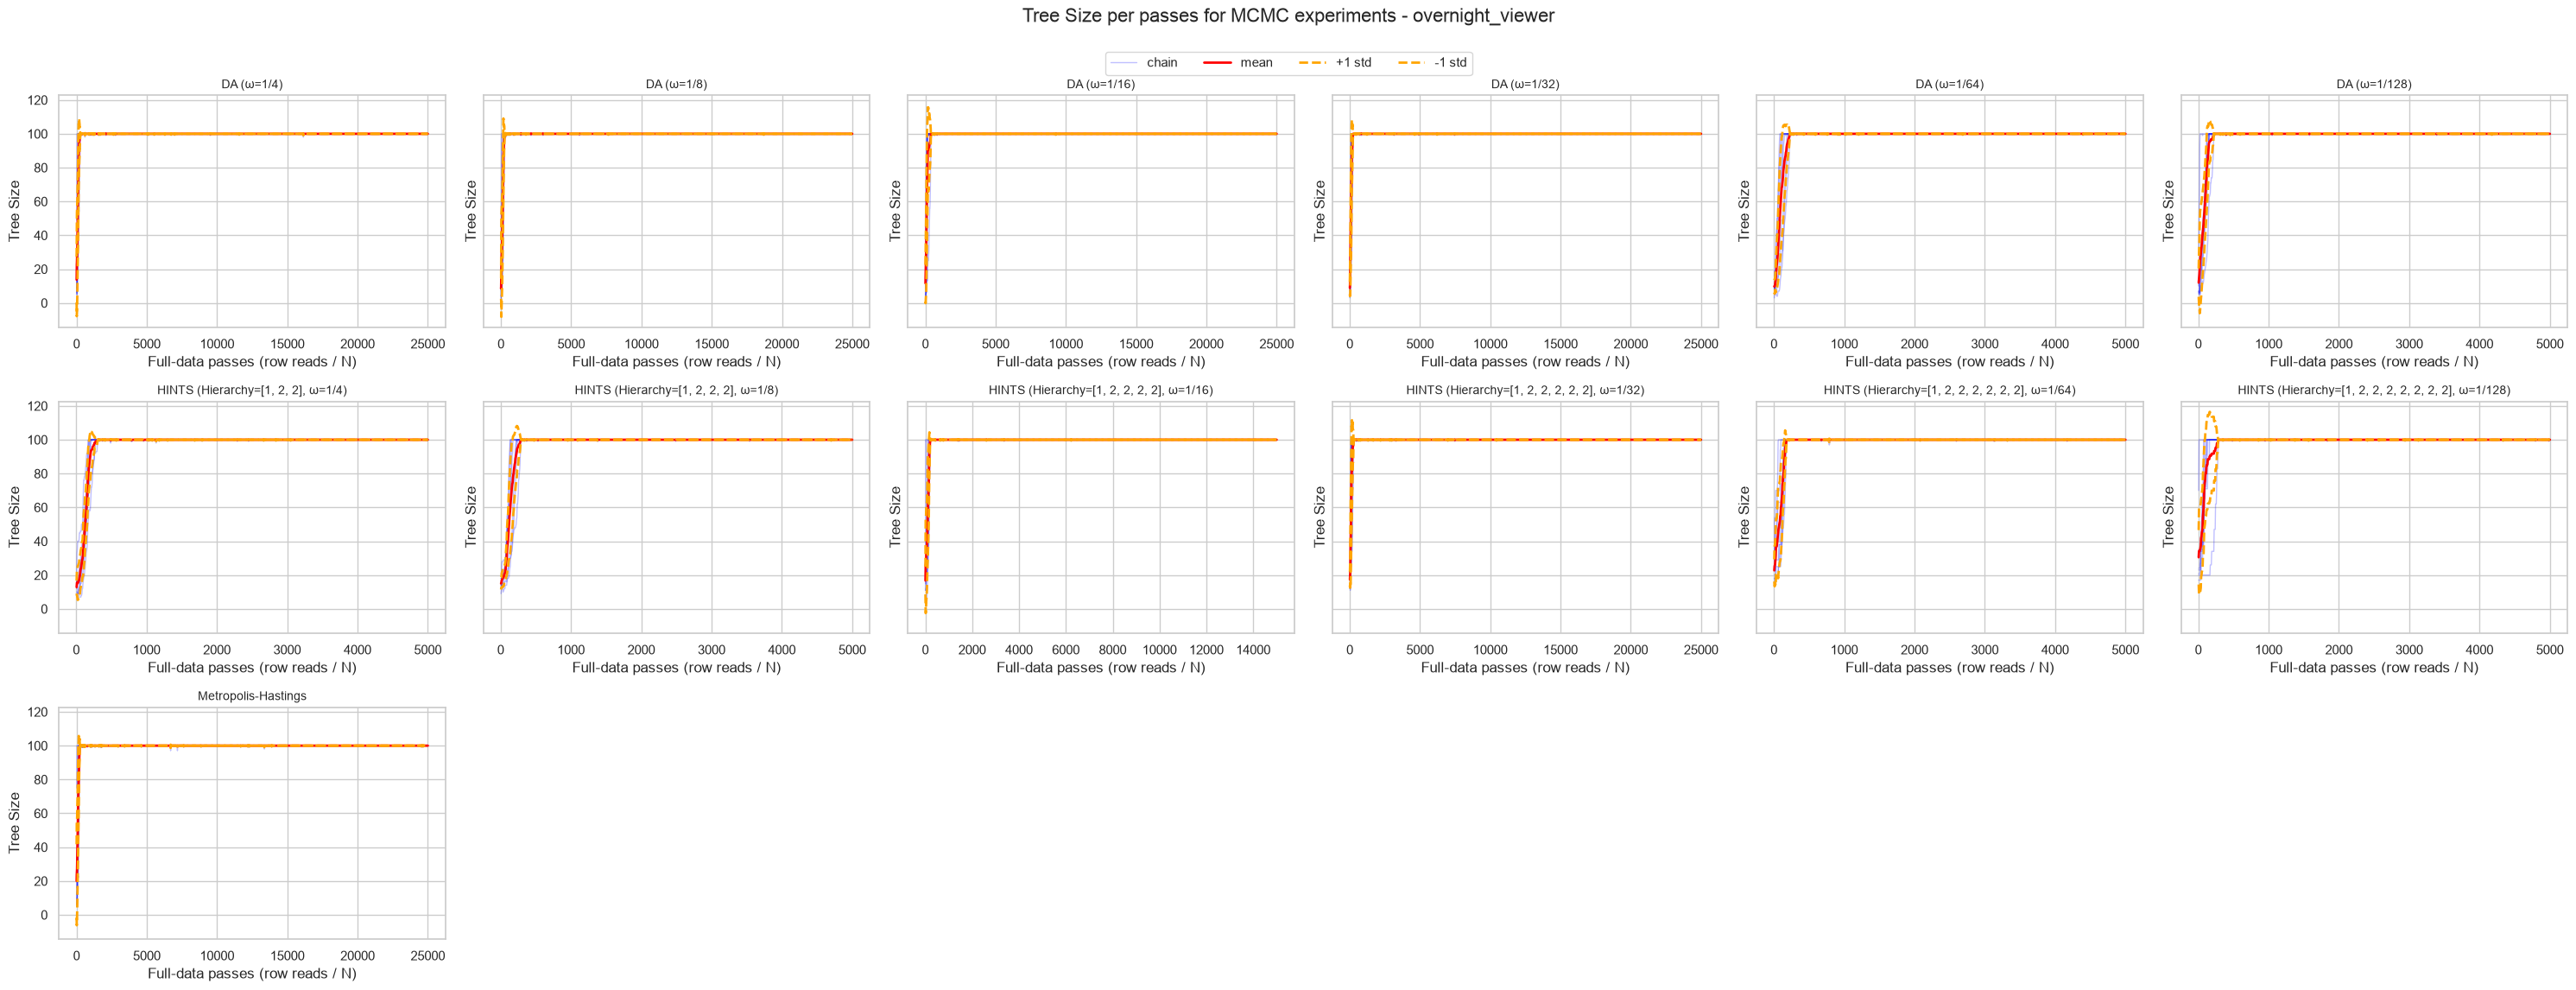

In [14]:
plot_chains(mcmc_results, "tree_len", "Tree Size")

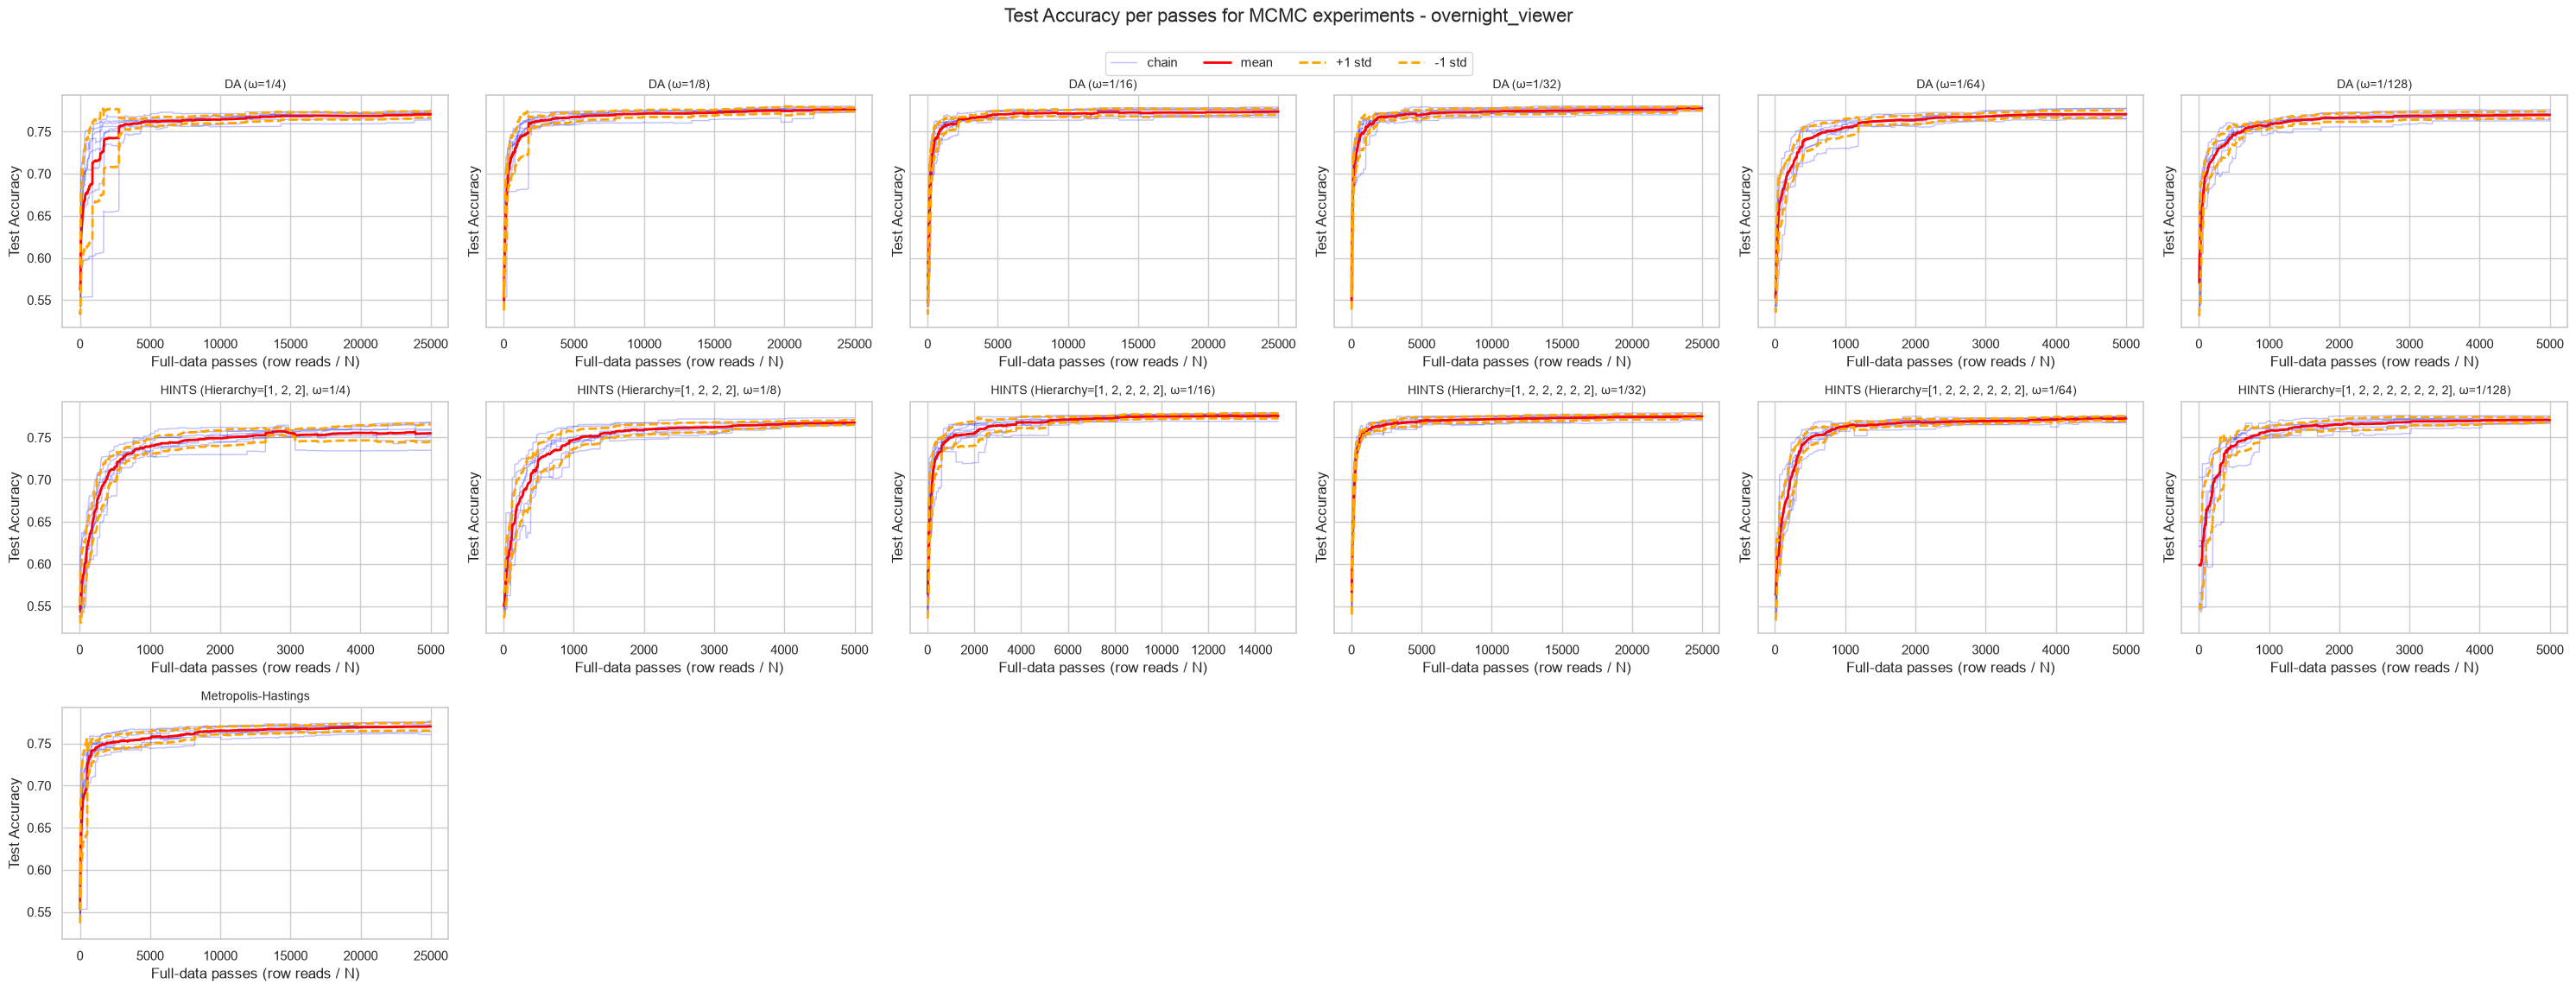

In [15]:
plot_chains(mcmc_results, "test_accuracy", "Test Accuracy")

## Against sampling time and iterations

Each chain's own clock and iteration count, averaged on a shared grid up to where the shortest chain stops. Time is wall-clock on whatever machine ran the chains: the stored MH and DA ran on Barkla, and the overnight runs on the laptop, under load.

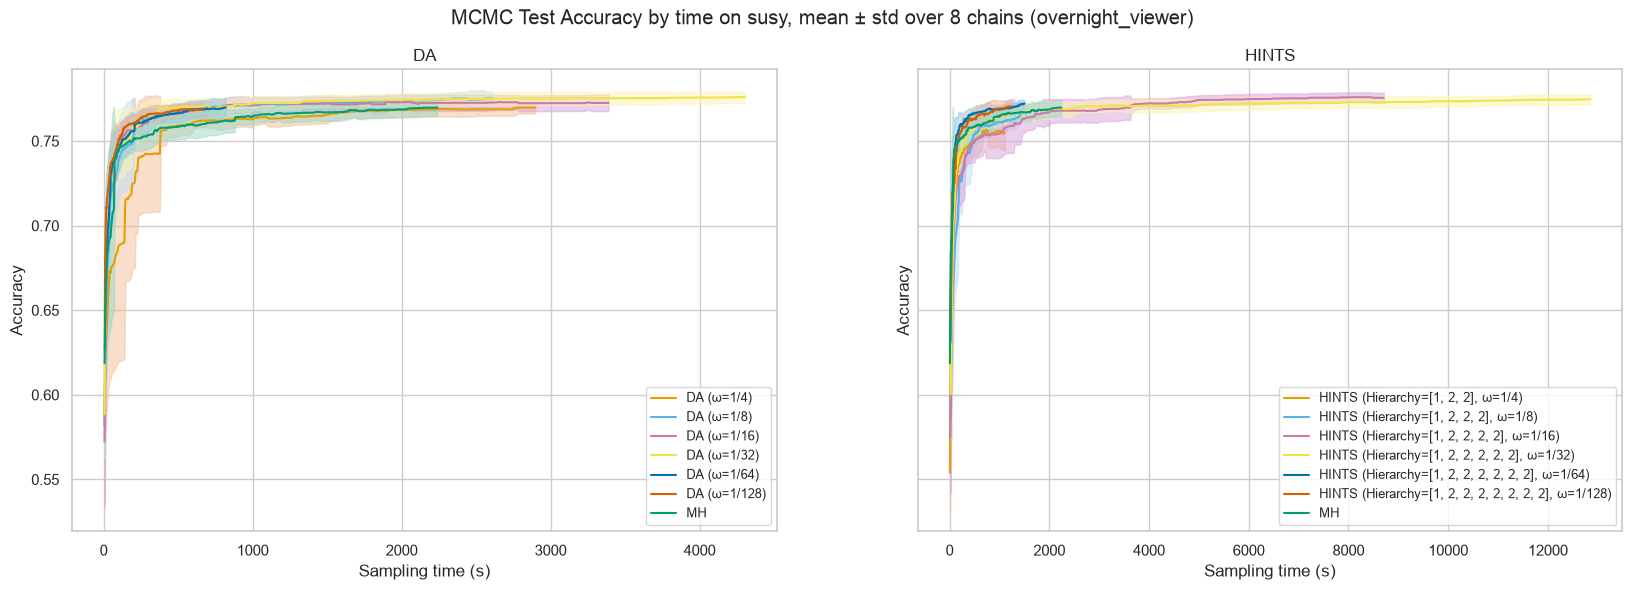

In [16]:
plot_metric_split(mcmc_results, "test_accuracy", "Test Accuracy", "Accuracy", x="time")

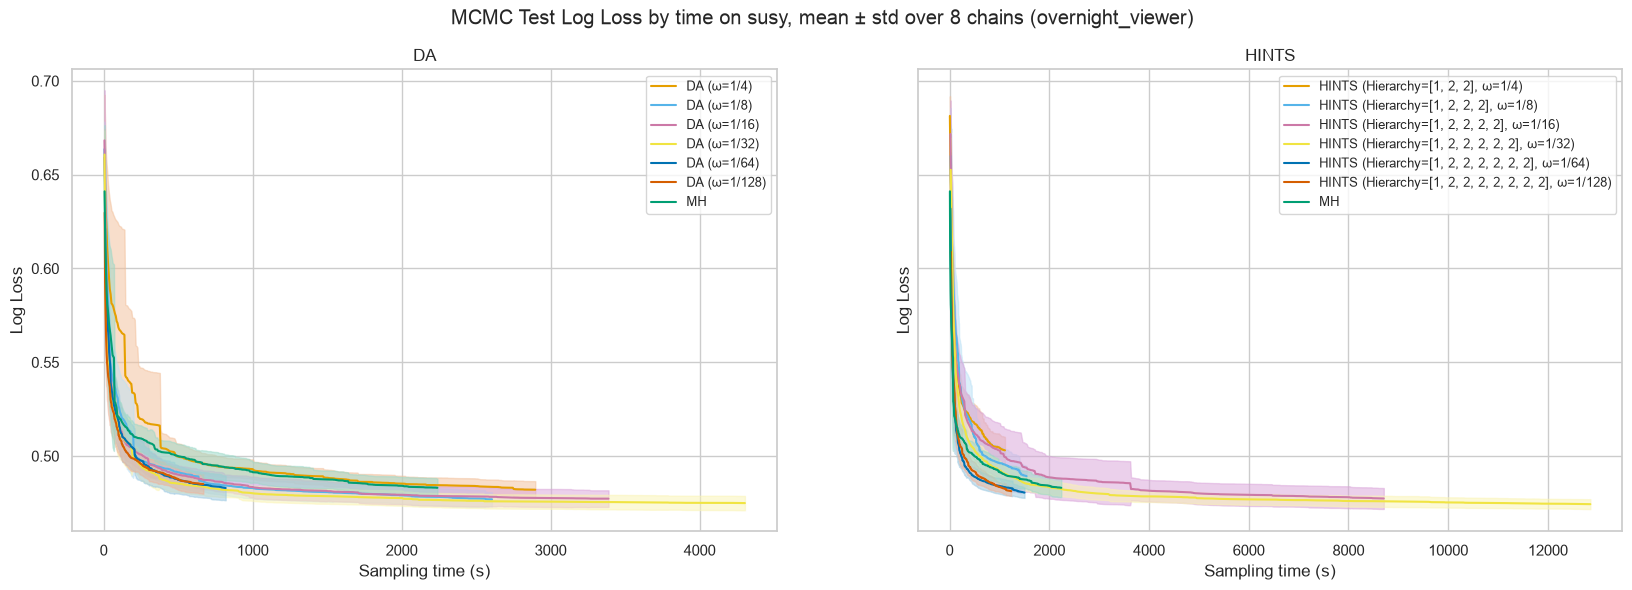

In [17]:
plot_metric_split(mcmc_results, "test_log_loss", "Test Log Loss", "Log Loss", x="time")

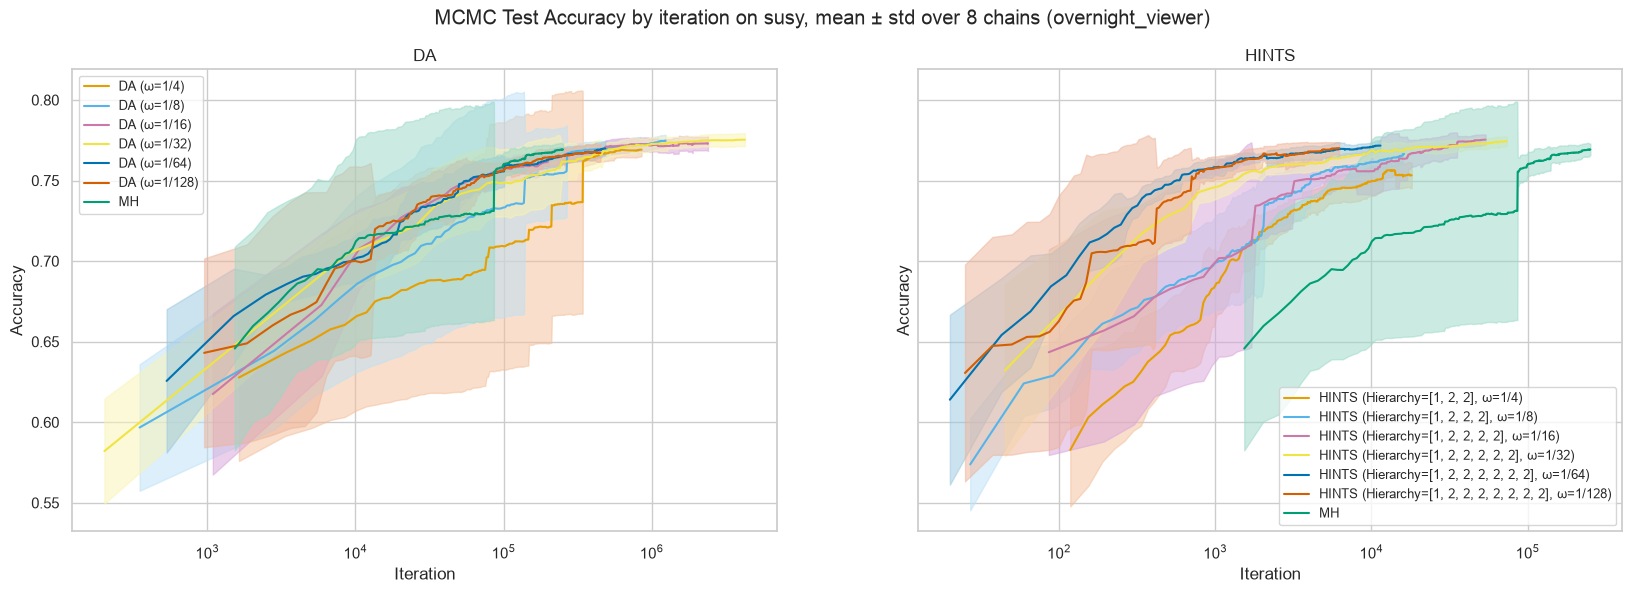

In [18]:
plot_metric_split(mcmc_results, "test_accuracy", "Test Accuracy", "Accuracy", x="iteration", logx=True)